# A — Cơ sở thiết kế và mô phỏng Front-End tham chiếu F0/s42

**Mục tiêu:** thiết lập cơ sở kỹ thuật cho cấu hình **F0/V1/seed 42**, dùng làm điểm khởi đầu khảo sát ở notebook B. A trình bày nguồn gốc lựa chọn tham số, khảo sát kiến trúc lịch sử và mô phỏng tác động của những phép xử lý tín hiệu. **Không lựa chọn Front-End hay checkpoint tối ưu** tại đây.

**Cấu hình xuất phát F0:** 
- WAV mono, 16 kHz, cửa sổ 5 giây
- Butterworth band-pass **100–2000 Hz, bậc 5**
- Pre-emphasis **α = 0,97**
- **64 Mel**, **FFT 1024**, **hop 625**. 
- Seed **42** là điều kiện cố định của vòng OFAT ban đầu, không hàm ý seed này tốt hơn các seed khác.

Pre-emphasis có tiền lệ trong một số pipeline trích xuất MFCC, bao gồm nhánh MFCC của bài [*Hybrid deep learning and YAMNet features for asthma diagnosis from respiratory sounds*](https://www.nature.com/articles/s41598-026-49247-y). Việc kế thừa α = 0,97 **chỉ tạo giả thuyết xuất phát**, chưa chứng minh thành phần này cần thiết cho Log-Mel/CNN.

**Cập nhật phần Butterworth:** A2 kết hợp cơ sở âm học của *wheeze*, tài liệu tham khảo và một **khảo sát phổ bổ sung trên 881 WAV Core TRAIN**. Khảo sát bổ sung này củng cố/giới hạn cách lý giải F0, **không phải một vòng chọn band-pass theo Accuracy**.

**Mạch nghiên cứu:** **A** (cơ sở F0/V1/s42) → **B0** (kiểm toán nguồn WAV, đọc song song trước khi diễn giải kết quả) → **B** (OFAT) → **C** (khảo sát tổ hợp) → **D** (lượng tử hóa và kiểm thử tĩnh) → **E** (kiểm chứng cuối và lựa chọn model).

## A1. Cấu hình tham chiếu F0 và phạm vi mô phỏng

| Thành phần | F0 — baseline khảo sát |
|---|---|
| Tín hiệu | Mono, 16 kHz, 5 giây (80.000 mẫu) |
| Butterworth band-pass | 100–2000 Hz, bậc 5 (cơ sở lựa chọn và giới hạn ở A2) |
| Pre-emphasis | `α = 0,97` |
| STFT | `n_fft = 1024`, Hann, `hop_length = 625` |
| Mel filterbank | `n_mels = 64`, dải 100–2000 Hz, thang Slaney |
| Tensor Log-Mel | `64 × 129 × 1` |
| Kiến trúc/seed tham chiếu | V1 / seed 42 |

Trong A, những giá trị khác như **bậc 3/7, α = 0/0,95, Mel40 hoặc FFT2048** được đưa vào **để minh họa tác động của tham số**, không phải công bố cấu hình được chọn. Các hình đáp ứng DSP không trực tiếp chứng minh Accuracy hoặc đặc trưng bệnh lý.

### A1.1. Vì sao chọn V1 làm kiến trúc tham chiếu cho khảo sát Front-End?

Trước khi khảo sát DSP, pipeline **AI_Training_Model lịch sử** dùng Front-End **F0** (`pre-emphasis α=0,97`, `Mel64`, `FFT1024`) để so sánh sơ bộ các kiến trúc. Pre-emphasis là một thành phần từng được sử dụng trong xử lý đặc trưng tiếng nói/MFCC, gồm cả nhánh MFCC của bài *Hybrid deep learning and YAMNet features for asthma diagnosis from respiratory sounds*. Vì thế, **giữ α=0,97 ở F0 là một điểm xuất phát để có đối chứng**, không có nghĩa tham số này đã được chứng minh tối ưu hoặc bắt buộc cho Log-Mel.

Bảng Phase 2 lịch sử (nguồn: báo cáo và output đã lưu tại `AI_Training_Model/Phase2_Preprocess_&_Traning/archive/`, các kết quả dưới đây là **Test FP32**, không phải phép chọn checkpoint mới). Cell Python ngay dưới bảng sẽ truy trực tiếp report/log để đối chứng:

| Kiến trúc | Số tham số | Test Accuracy | Nhận xét |
|---|---:|---:|---|
| **V1 — DS-CNN + Flatten** | 527.994 | **89,31%** | Kiến trúc Separable CNN dùng làm tham chiếu |
| V2 — DS-CNN + GAP | 7.802 | 86,79% | Rất gọn nhưng Accuracy thấp hơn V1 |
| V3 — HelloEdge DS-CNN | 23.617 | 86,16% | Phương án nhúng gọn nhẹ |
| V4.0 — MobileNetV1-style | 1.371.361 | 86,79% | Nhiều tham số |
| V4.1 — MobileNetV1-style | 480.321 | 79,87% | Chất lượng phân loại thấp trong khảo sát ban đầu |
| **V5 — CNN một nhánh, tham khảo E-RespiNet** | 548.161 | **91,82%** | Accuracy cao nhất ở vòng F0, không phải E-RespiNet ba nhánh đầy đủ |
| V6 — Separable CNN + GAP | 8.401 | 81,13% | Nhỏ nhưng chất lượng chưa đáp ứng mục tiêu |

**V1 không phải model có Accuracy cao nhất ở vòng F0:** V5 đạt 91,82%, cao hơn V1 (89,31%). Tuy nhiên, V1 được **chọn sơ bộ** để cố định kiến trúc trong các thí nghiệm Front-End vì sử dụng các lớp `SeparableConv2D`, có chất lượng phân loại cạnh tranh và phù hợp với định hướng đánh giá TinyML trên ESP32-S3. Ở giai đoạn này, **chưa khẳng định V1 có latency thấp nhất hay tối ưu trên phần cứng**.

Do đó, notebook **B** bắt đầu từ **F0/V1/seed 42** và thay đổi từng tham số DSP (OFAT). **C** mới khảo sát tương tác tham số và nhiều seed, **D** tiếp tục đánh giá lượng tử hóa và kiểm thử tĩnh, còn **E** kiểm chứng lựa chọn kiến trúc trên cấu hình Front-End đã được khảo sát. Như vậy, việc cố định V1 tại A là **quyết định thiết kế thí nghiệm ban đầu**, không phải kết luận kiến trúc triển khai được giả định trước.


In [1]:
from pathlib import Path
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display

def find_project_root():
    override = os.environ.get('NCKH_PROJECT_ROOT')
    starts = [Path(override).expanduser().resolve()] if override else []
    here = Path.cwd().resolve()
    starts.extend([here, *here.parents])
    for base in starts:
        if (base / 'AI_Training_Model' / 'Phase2_Preprocess_&_Traning').is_dir():
            return base.resolve()
    return None

# Các output được train vs bộ tham số F0 được lưu theo link dưới
PROJECT_ROOT = find_project_root()
PHASE2_ARCHIVE = (
    PROJECT_ROOT / 'AI_Training_Model' / 'Phase2_Preprocess_&_Traning' / 'archive'
    if PROJECT_ROOT else None
)
ARCHITECTURE_ARCHIVE = {
    'V1 - DS-CNN + Flatten': ('Output_Train_V1_SepConv2D_Flatten', 'log_train_v1.log'),
    'V2 - DS-CNN + GAP': ('Output_Train_V2_SeqConv2D_Global', 'log_train_v2.log'),
    'V3 - HelloEdge DS-CNN': ('Output_Train_V3_HelloEdge', 'log_train_v3.log'),
    'V4.0 - MobileNetV1-style': ('Output_Train_V4_0_MobileNet', 'log_train_v4_0.log'),
    'V4.1 - MobileNetV1-style': ('Output_Train_V4_1_MobileNet', 'log_train_v4_1.log'),
    'V5 - CNN tham khảo E-RespiNet': ('Output_Train_V5_ERespiNet', 'log_train_v5.log'),
    'V6 - Separable CNN + GAP': ('Output_Train_V6_SepConv2D_GAP', 'log_train_v6.log'),
}

def first_match(text, pattern, cast=float):
    match = re.search(pattern, text, flags=re.IGNORECASE | re.MULTILINE)
    return cast(match.group(1).replace(',', '')) if match else np.nan

architecture_rows = []
if PHASE2_ARCHIVE is None or not PHASE2_ARCHIVE.is_dir():
    print('CHƯA TÌM THẤY Phase 2 archive; đặt NCKH_PROJECT_ROOT nếu notebook nằm ngoài repo.')
else:
    for architecture, (folder_name, log_name) in ARCHITECTURE_ARCHIVE.items():
        folder = PHASE2_ARCHIVE / folder_name
        report_path = folder / 'Test_Report.txt'
        log_path = folder / log_name
        if not report_path.is_file() or not log_path.is_file():
            raise FileNotFoundError(f'{architecture}: thiếu {report_path} hoặc {log_path}')
        report_text = report_path.read_text(encoding='utf-8', errors='replace')
        log_text = log_path.read_text(encoding='utf-8', errors='replace')
        architecture_rows.append({
            'Kiến trúc': architecture,
            'Số tham số': int(first_match(log_text, r'Total params:\s*([0-9,]+)', int)),
            'Test Accuracy (%)': 100 * first_match(report_text, r'Test Accuracy:\s*([0-9.]+)'),
            'Test Report': str(report_path),
            'Training Log': str(log_path),
        })

ARCHITECTURE_EVIDENCE = pd.DataFrame(architecture_rows)
if not ARCHITECTURE_EVIDENCE.empty:
    assert len(ARCHITECTURE_EVIDENCE) == 7
    display(ARCHITECTURE_EVIDENCE[['Kiến trúc', 'Số tham số', 'Test Accuracy (%)']].round(3))
    print('Nguồn Phase 2 archive:', PHASE2_ARCHIVE)

FS, LOW, HIGH, ORDER = 16_000, 100, 2_000, 5
N_SAMPLES, HOP, FFT_F0, MEL_F0 = 80_000, 625, 1024, 64
print(f'F0/V1/s42 (mốc B): sample rate={FS} Hz; samples={N_SAMPLES}; bandpass={LOW}-{HIGH} Hz; n_fft={FFT_F0}; n_mels={MEL_F0}; alpha=0.97; hop={HOP}')
print('Phạm vi: mô phỏng đáp ứng DSP, KHÔNG tái tạo kết quả phân loại từ waveform nghiên cứu.')

,Kiến trúc,Số tham số,Test Accuracy (%)
0,V1 - DS-CNN + Flatten,527994,89.308
1,V2 - DS-CNN + GAP,7802,86.792
2,V3 - HelloEdge DS-CNN,23617,86.164
3,V4.0 - MobileNetV1-style,1371361,86.792
4,V4.1 - MobileNetV1-style,480321,79.874
5,V5 - CNN tham khảo E-RespiNet,548161,91.824
6,V6 - Separable CNN + GAP,8401,81.132


Nguồn Phase 2 archive: D:\NCKH_2026\NCKH_2026_AIOT\AI_Training_Model\Phase2_Preprocess_&_Traning\archive
F0/V1/s42 (mốc B): sample rate=16000 Hz; samples=80000; bandpass=100-2000 Hz; n_fft=1024; n_mels=64; alpha=0.97; hop=625
Phạm vi: mô phỏng đáp ứng DSP, KHÔNG tái tạo kết quả phân loại từ waveform nghiên cứu.


## A2. Đáp ứng Butterworth: cơ sở kiểm soát dải 100–2000 Hz

Mô phỏng đáp ứng tần số của các bộ lọc Butterworth bậc **3/5/7** với cùng cutoff nhằm làm rõ tác động của bậc lọc lên độ dốc vùng chuyển tiếp. **F0 sử dụng bậc 5**, việc đối chiếu bậc khác ở đây chỉ mang tính cơ sở DSP, không xác nhận bậc 5 cho Accuracy tối ưu.

Với prototype low-pass Butterworth bậc `N`, bình phương đáp ứng biên độ có dạng:

$$
|H_{LP}(jΩ)|^2 = 1 / [1 + (Ω/Ω_c)^{2N}]
$$

Butterworth không có gợn trong passband và đạt `|H|=1/√2`, tương đương khoảng `−3,01 dB`, tại tần số cutoff. Để chuyển prototype sang band-pass với biên dưới `Ω_L` và biên trên `Ω_H`, dùng phép ánh xạ:

$$
Ω_p = (Ω^2 - Ω_0^2)/(BΩ),
\qquad Ω_0 = (Ω_LΩ_H)^{1/2},
\qquad B = Ω_H - Ω_L
$$

suy ra đáp ứng biên độ band-pass lý tưởng theo prototype:

$$
|H_{BP}(jΩ)| = [1 + |Ω_p|^{2N}]^{-1/2}
$$

Trong triển khai số, `scipy.signal.butter(..., output='sos')` biểu diễn bộ lọc thành chuỗi các section bậc hai để ổn định số học:

$$
H(z) = ∏_{m=1}^{K}
(b_{0,m} + b_{1,m}z^{-1} + b_{2,m}z^{-2})
/(a_{0,m} + a_{1,m}z^{-1} + a_{2,m}z^{-2})
$$

và độ lợi trên biểu đồ được tính bởi:

$$
G_{dB}(f) = 20 log_{10}|H(e^{j2πf/f_s})|
$$

Với lời gọi SciPy `order=5` cho band-pass, phép biến đổi tạo bộ lọc số có bậc tổng thể `10`, được lưu dưới dạng `5` biquad SOS. Hai cutoff 100 Hz và 2000 Hz xấp xỉ các điểm `−3 dB`; tăng `N` làm vùng chuyển tiếp dốc hơn nhưng cũng tăng chi phí tính toán và độ nhạy số học.

**Phân biệt chế độ lọc:** Đồ thị đáp ứng từ `sosfreqz` trong cell dưới biểu diễn **một lượt lọc**. Phân tích WAV bổ sung sử dụng `sosfiltfilt` (tiến–lùi, zero-phase), có đáp ứng biên độ hiệu dụng `|H(f)|²` và độ lợi dB xấp xỉ **gấp đôi** so với một lượt lọc. Hình minh họa chỉ phục vụ giải thích DSP; chưa dùng để kết luận parity với Front-End train/firmware.

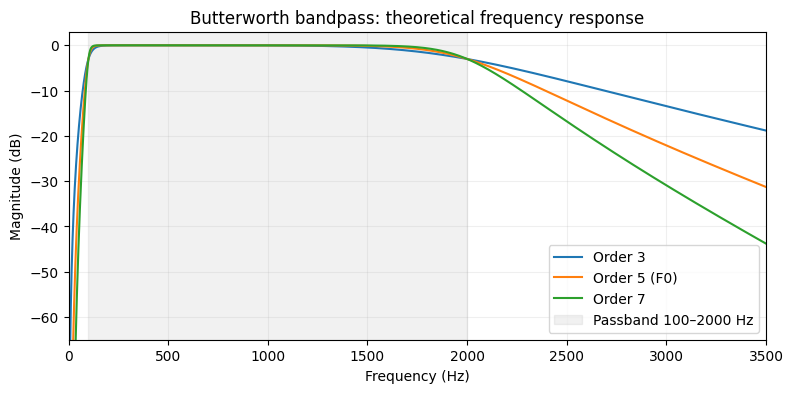

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
for order in [3, 5, 7]:
    sos = signal.butter(order, [LOW, HIGH], btype='bandpass', fs=FS, output='sos')
    hz, response = signal.sosfreqz(sos, worN=8192, fs=FS)
    db = 20*np.log10(np.maximum(abs(response), 1e-10))
    ax.plot(hz, db, label=f'Order {order}' + (' (F0)' if order==5 else ''))
ax.axvspan(LOW, HIGH, color='grey', alpha=.11, label='Passband 100–2000 Hz')
ax.set(xlim=(0, 3500), ylim=(-65, 3), xlabel='Frequency (Hz)', ylabel='Magnitude (dB)', title='Butterworth bandpass: theoretical frequency response')
ax.grid(alpha=.2); ax.legend(); plt.show()

### A2.1. Cơ sở chọn dải 100–2000 Hz: đặc tính tiếng rít và nghiên cứu trước

Dải band-pass của **F0** là **lựa chọn thiết kế ban đầu**, được đặt trong bối cảnh ba cơ sở bổ trợ nhau:

1. **Đặc tính âm học của tiếng rít (*wheeze*).** Tiếng rít thường có cấu trúc âm sắc/đỉnh phổ tương đối hẹp, có thể xuất hiện từ vài trăm Hz đến trên 1 kHz. Tổng quan của **Reichert và cộng sự (2008)** mô tả wheeze trong khoảng **100–2500 Hz**, với tần số cơ bản thay đổi theo nguồn nghiên cứu (xấp xỉ **100–1600 Hz**). Vì vậy, 100–2000 Hz bao phủ **một phần quan trọng của vùng quan tâm**, nhưng **có thể bỏ sót** thành phần wheeze trên 2000 Hz. Nhãn *Asthma* của một WAV **không bảo đảm** mọi đoạn 5 giây đều chứa tiếng rít.
2. **Tiền lệ xử lý tín hiệu.** **Pramono, Imtiaz và Rodriguez-Villegas (2019)** trong *Evaluation of features for classification of wheezes and normal respiratory sounds* sử dụng **Butterworth bậc 5, band-pass 150–2000 Hz** nhằm giảm thành phần dưới 150 Hz (ví dụ tiếng tim và DC offset trong dữ liệu của họ). **F0 của đề tài không dùng đúng dải đó**: cận dưới **100 Hz** cho phép giữ thêm vùng **100–150 Hz**, còn cận trên 2000 Hz tương tự nghiên cứu tham khảo. Đây là **định hướng lựa chọn**, chưa phải bằng chứng 100 Hz tốt hơn 150 Hz về Accuracy.
3. **Giới hạn băng thông nguồn dữ liệu.** Nhiều WAV Core gốc được ghi ở **4 kHz**, tức **Nyquist 2000 Hz**. Chuyển chúng lên 16 kHz không tạo thêm thông tin phổ trên 2000 Hz. Dải chung 100–2000 Hz tạo phạm vi phân tích gần mức băng thông khả dụng của nhóm nguồn này, dù không loại bỏ được khác biệt thiết bị/nguồn thu giữa các nhãn.

**Tài liệu tham khảo:** [Pramono và cs. (2019), PLOS ONE, DOI: 10.1371/journal.pone.0213659](https://doi.org/10.1371/journal.pone.0213659) · [Reichert và cs. (2008), *Analysis of Respiratory Sounds: State of the Art*](https://pmc.ncbi.nlm.nih.gov/articles/PMC2990233/).


### A2.2. Khảo sát phổ bổ sung trên TRAIN: 881 WAV Core

**Quy trình:** script `00b_Bandpass_Frontend_Evidence.py --all-raw` khảo sát **228 Asthma + 653 Non-Asthma = 881 WAV Core TRAIN**, loại augmentation/environment/playback, sử dụng cửa sổ 5 giây theo `frontend_core`, tính Welch PSD **trước band-pass**, sau khi chuẩn hóa đỉnh từng WAV. Chỉ thống kê băng tần được hỗ trợ bởi **Nyquist của WAV gốc**; không coi phần phổ không có thông tin sau resample là bằng 0. Số liệu bên dưới là **trung vị theo WAV**, không phải trung vị theo người bệnh hay phép đo trên các đoạn được xác nhận là wheeze.

| Nhãn | Sample rate nguồn | Số WAV | Trung vị PSD 0–100 Hz | Trung vị PSD 100–2000 Hz |
|---|---|---:|---:|---:|
| Asthma | ≤4 kHz | 205 | 99.100% | 0.779% |
| Asthma | >4 kHz | 23 | 99.428% | 0.516% |
| Non-Asthma | ≤4 kHz | 165 | 99.224% | 0.624% |
| Non-Asthma | >4 kHz | 488 | 98.073% | 1.672% |

**Nhận xét:** hầu hết năng lượng Welch PSD của những bản ghi này tập trung **dưới 100 Hz**, cho thấy bộ lọc có khả năng suy giảm một thành phần thấp tần lớn. Tuy nhiên, **không thể mặc định toàn bộ phần bị cắt là nhiễu** hoặc suy ra rằng càng giảm RMS thì khả năng nhận diện càng tốt. Hai nhãn có cơ cấu sample rate rất khác nhau (**Asthma ≤4 kHz: 205/228; Non-Asthma >4 kHz: 488/653**), nên hình dạng phổ cũng có thể phản ánh nguồn ghi âm, không chỉ đặc điểm hô hấp.

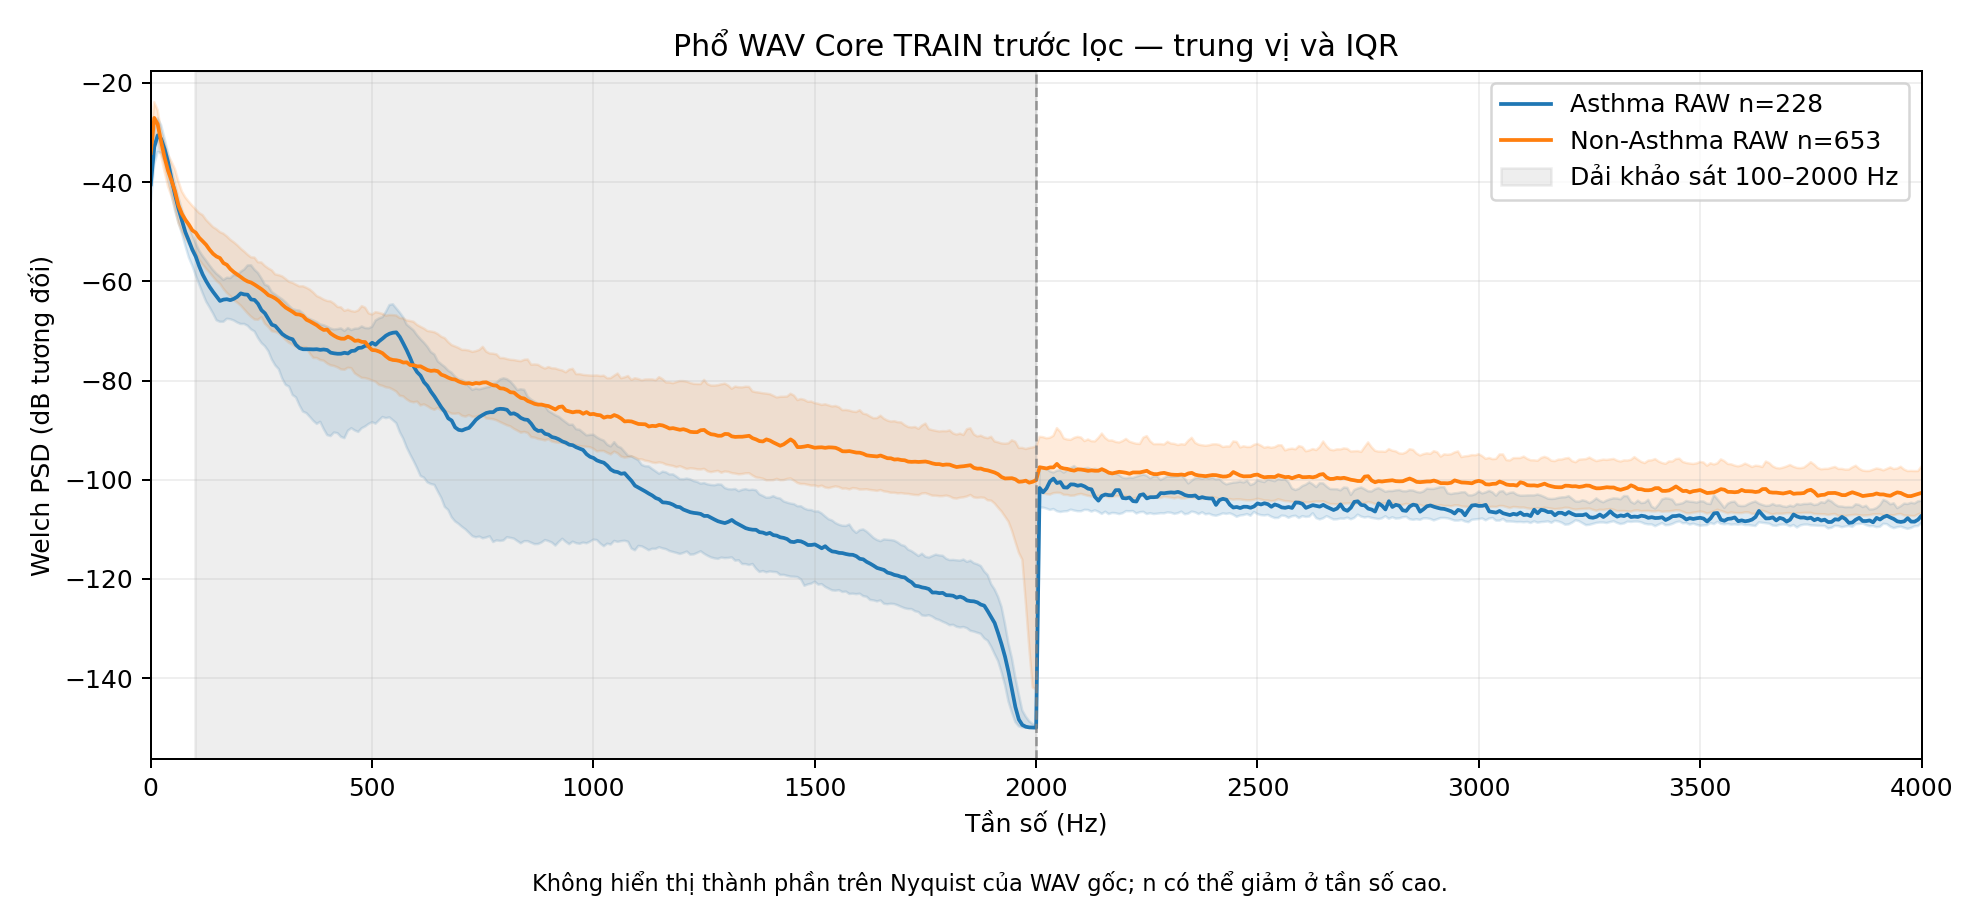

*Hình A2.1 — Phổ Welch trước lọc theo nhãn, biểu diễn trung vị và IQR; vùng xám là dải 100–2000 Hz. Dải trên Nyquist WAV gốc không được sử dụng.*

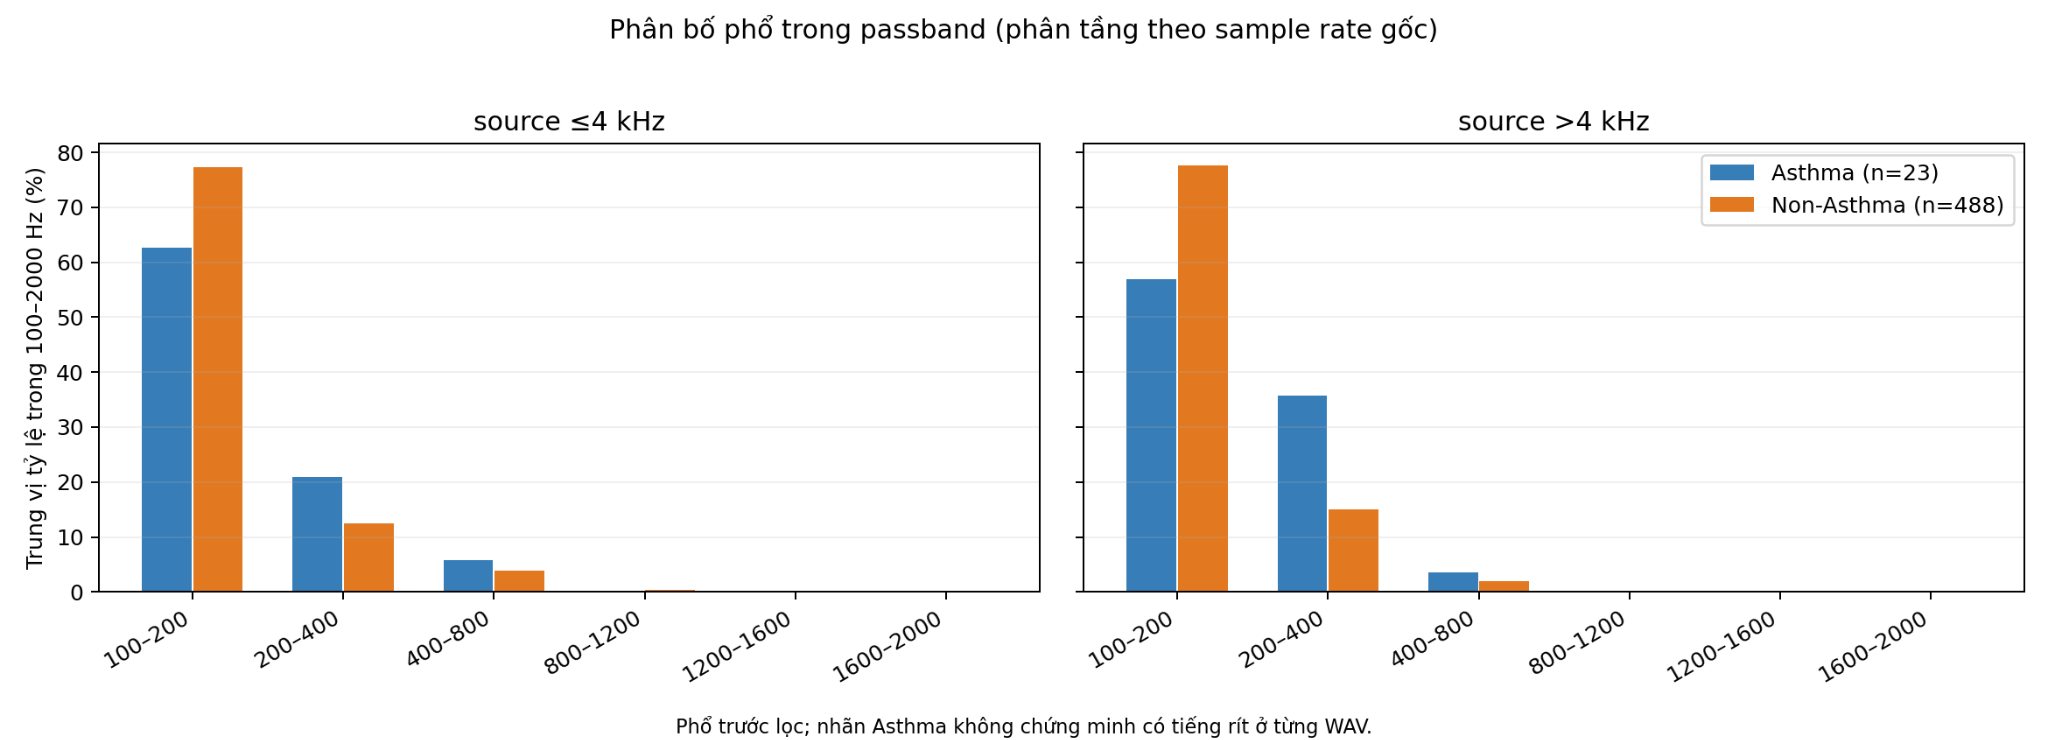

*Hình A2.2 — Phân bố PSD giữa các dải con, chuẩn hóa trên 100–2000 Hz và phân tầng theo sample rate nguồn. Năng lượng thấp ở 800–2000 Hz không chứng minh vùng này vô ích cho phát hiện wheeze vì một đỉnh phổ hẹp/ngắn có thể có ít năng lượng trung bình.*


### A2.3. Đối chiếu các dải ứng viên và quyết định tham chiếu F0

Các giá trị sau là **trung vị tỷ lệ PSD trước lọc so với tổng năng lượng trong dải khả dụng của WAV gốc**; chúng **không phải** Accuracy hoặc lượng năng lượng bảo toàn chính xác sau bộ lọc:

| Dải tần | Asthma nguồn ≤4 kHz (n=205) | Non-Asthma nguồn >4 kHz (n=488) |
|---|---:|---:|
| 50-2000 Hz | 4.306% | 5.473% |
| 80-2000 Hz | 1.146% | 2.289% |
| 100-2000 Hz | 0.779% | 1.672% |
| 150-2000 Hz | 0.384% | 0.671% |
| 100-1500 Hz | 0.779% | 1.672% |

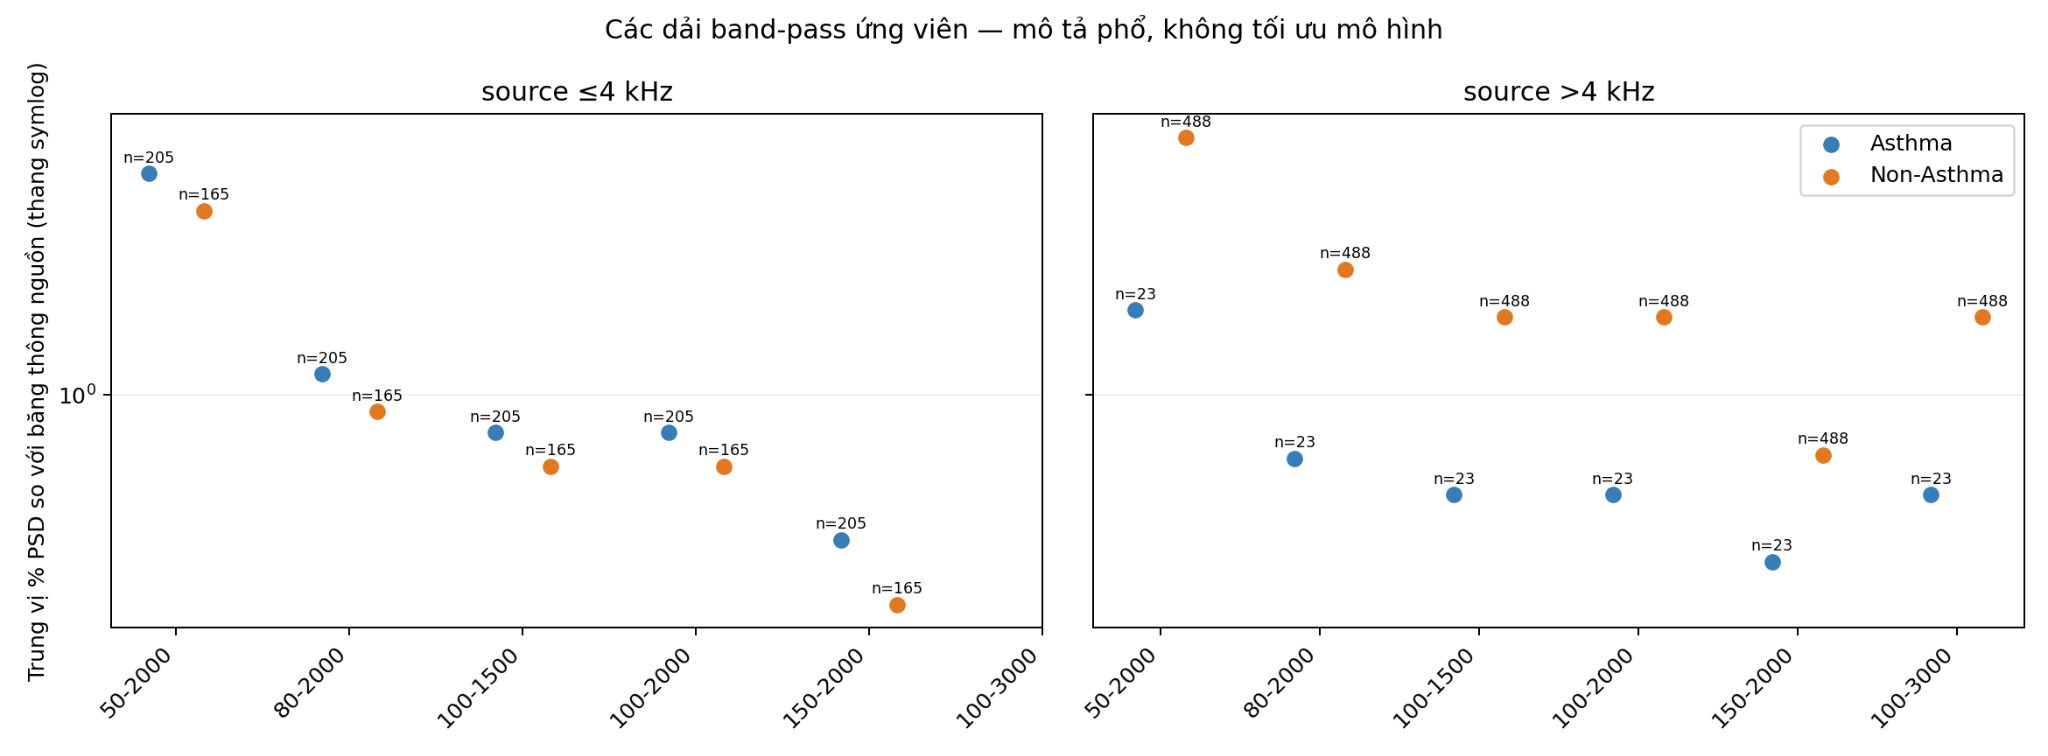

*Hình A2.3 — Năng lượng PSD nguồn trong các dải ứng viên, trục tung log đối xứng; nhóm nguồn 4 kHz không có dữ liệu nguồn trên 2000 Hz.*

- **50–2000 / 80–2000 Hz:** giữ nhiều năng lượng hơn, nhưng kéo theo thêm vùng 50–100 Hz chiếm tỷ lệ lớn; không mặc định là tốt hơn cho mô hình.
- **150–2000 Hz:** gần phương án Pramono (2019), nhưng lược bỏ thêm vùng **100–150 Hz** mà F0 giữ lại.
- **100–1500 Hz:** có tỷ lệ năng lượng gần 100–2000 Hz ở nhiều WAV, song một đặc trưng tiếng rít hẹp ở 1500–2000 Hz vẫn có thể hữu ích mặc dù công suất trung bình nhỏ.

**Kết luận thiết kế:** lựa chọn **Butterworth bậc 5, 100–2000 Hz** là điểm xuất phát **có cơ sở âm học, tài liệu tham khảo và dữ liệu phổ TRAIN hỗ trợ một phần**; dải và bậc lọc được **giữ cố định** trong OFAT/factorial để kiểm soát số biến. Khảo sát phổ này được **bổ sung sau khi F0 đã được hình thành**, không phải một phép chọn dải lọc có kiểm định trên Validation/Test, cũng **chưa chứng minh 100–2000 Hz tối ưu theo Accuracy**. Phần triển khai còn cần đối chiếu bộ lọc train và DSP trên phần cứng để xác nhận parity.


### A2.4. Minh họa Butterworth trên mẫu WAV hô hấp thực

Bên cạnh khảo sát trên toàn TRAIN, hình dưới lưu lại một phép lọc minh họa lịch sử dùng **`lfilter` (một lượt)**, khác với hình minh họa mới dùng **`sosfiltfilt` (tiến–lùi)** trong script phổ bổ sung. Hình dưới minh họa Butterworth band-pass 100–2000 Hz, bậc 5, thực hiện bằng `scipy.signal.lfilter` trên mẫu `P14WheezingRS_68.wav` (mono, resample 16 kHz). Hình gồm waveform trước/sau lọc và phổ Welch, được **lưu từ phép phân tích riêng**; notebook A chỉ nhúng ảnh để tham khảo, không cần WAV nguồn để tái tạo các mô phỏng lý thuyết.

[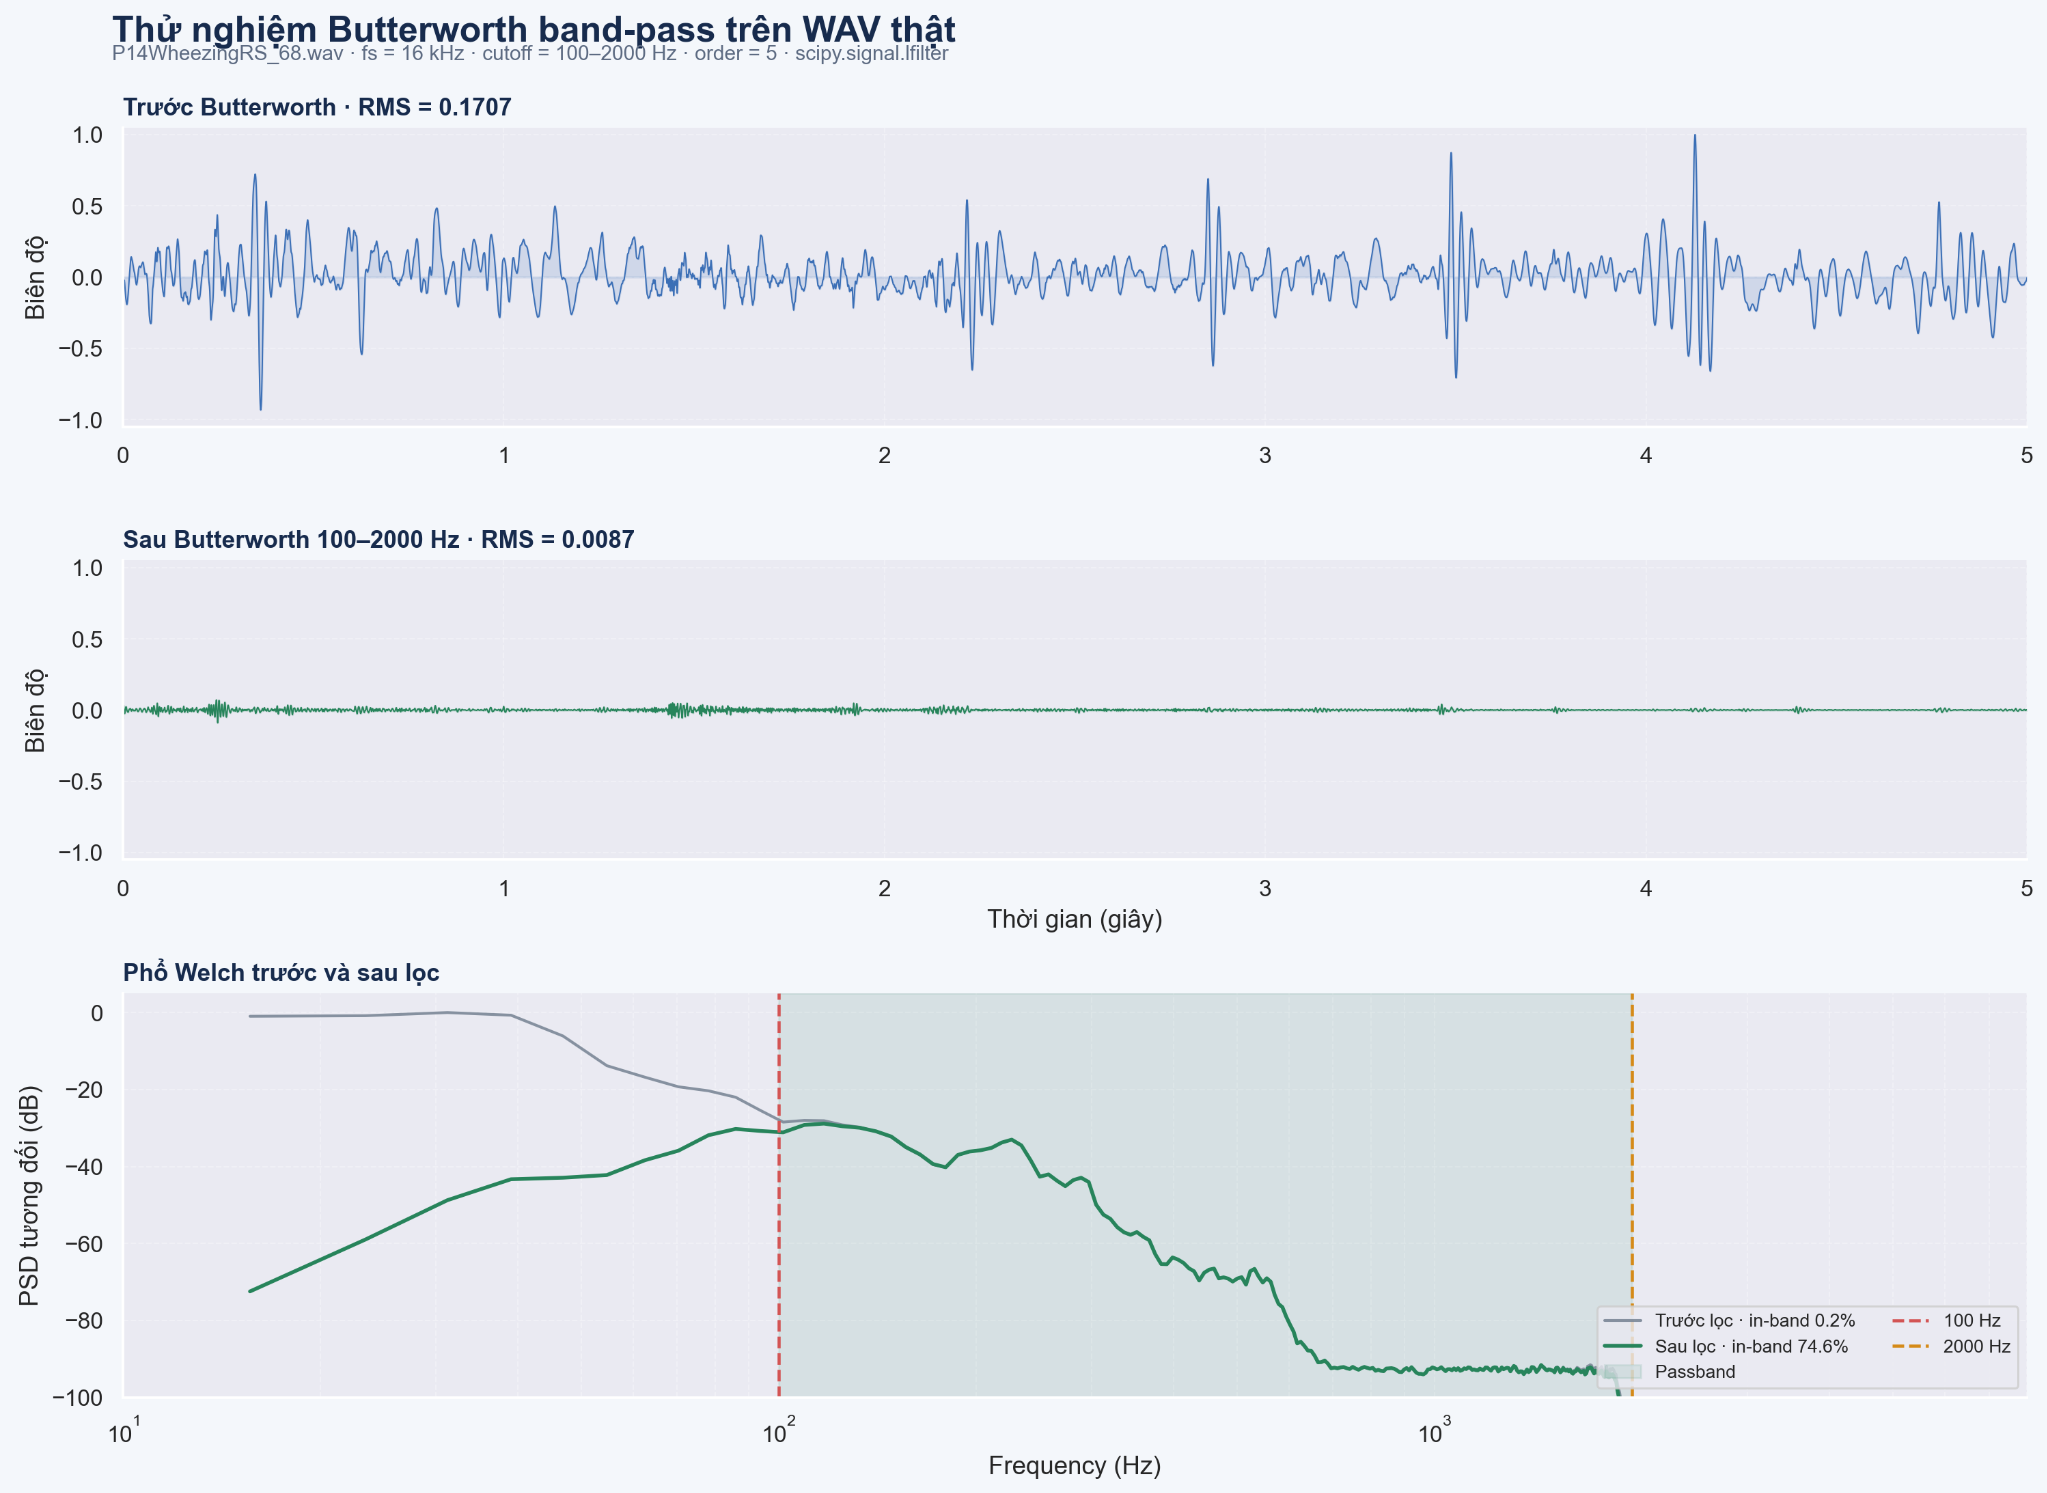](../../../../../ESP32_Standalone_Modules_Test/Audio_Visualizations/Butterworth_Audio_Experiment/P14WheezingRS_68_Butterworth_Before_After.png)

**Hình A2.4 —** Tác động của Butterworth band-pass 100–2000 Hz, bậc 5, trên một mẫu âm thanh hô hấp thực.

[Mở ảnh nguồn trong `ESP32_Standalone_Modules_Test`](../../../../../ESP32_Standalone_Modules_Test/Audio_Visualizations/Butterworth_Audio_Experiment/P14WheezingRS_68_Butterworth_Before_After.png) · [Xem script tạo ảnh](../../../../../ESP32_Standalone_Modules_Test/Audio_Visualizations/Apply_Butterworth_To_Audio.py)


**Nhận xét:** Ở mẫu này, các thành phần ngoài dải bị suy giảm mạnh; phổ sau lọc tập trung tương đối nhiều hơn trong dải 100–2000 Hz. RMS trên hình giảm từ **0,1707** xuống **0,0087**: nhiều thành phần năng lượng của tín hiệu ghi ban đầu nằm ngoài dải và **bị suy giảm**, nhưng không thể khẳng định tất cả đều là nhiễu hay thông tin hô hấp hữu ích bị giữ nguyên. Đây là **một ví dụ minh họa**, không chứng minh cutoff được chọn là tối ưu cho toàn bộ dữ liệu hoặc mọi tiếng wheezing.

## A3. Đáp ứng pre-emphasis `α=0`, `0,95`, `0,97`

Bộ lọc pre-emphasis bậc một được định nghĩa bởi phương trình sai phân:

$$
y[n] = x[n] - αx[n-1]
$$

Biến đổi Z cho hàm truyền:

$$
H(z) = Y(z)/X(z) = 1 - αz^{-1}
$$

Trên đường tròn đơn vị `z = e^{jω}`, đáp ứng tần số và biên độ là:

$$
H(e^{jω}) = 1 - αe^{-jω}
$$

$$
|H(e^{jω})| = \sqrt{1 + α^2 - 2α \cos(ω)}
$$

với `ω = 2πf/f_s`. Độ lợi được biểu diễn theo decibel:

$$
G_{dB}(f) = 20 \log_{10}|H(e^{j2πf/f_s})|
$$

Khi `α=0`, ta có `H(z)=1` và độ lợi bằng `0 dB` ở mọi tần số: tín hiệu được giữ nguyên. Khi `0<α<1`, độ lợi tại DC là `|1-α|`, còn tại tần số Nyquist là `1+α`; vì vậy thành phần thấp tần bị **suy giảm tương đối** mạnh hơn thành phần cao tần. Với `α=0,97`, DC bị suy giảm khoảng `−30,46 dB`, trong khi tại Nyquist độ lợi xấp xỉ `+5,89 dB`.

Biểu đồ dưới đây chỉ mô phỏng đáp ứng của bộ lọc. Nó không tự chứng minh thông tin bệnh lý bị mất hoặc Accuracy thay đổi, vì đặc trưng cuối còn phụ thuộc Log-Mel, normalization và mô hình phân loại.

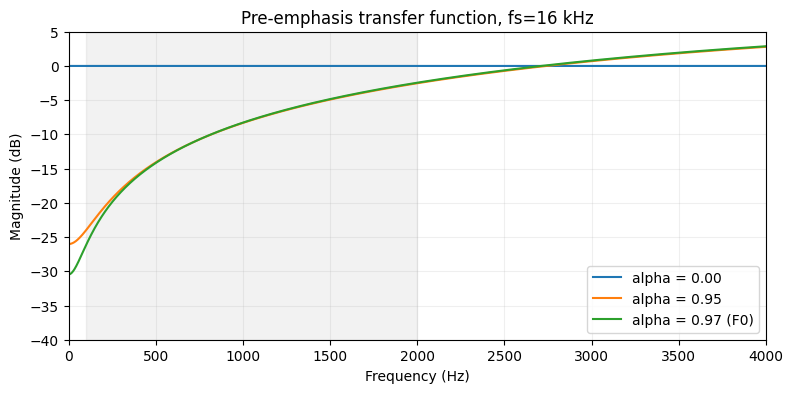

 100 Hz: alpha 0.97 gain = -26.21 dB
 200 Hz: alpha 0.97 gain = -21.62 dB
 500 Hz: alpha 0.97 gain = -14.18 dB
1000 Hz: alpha 0.97 gain = -8.28 dB
2000 Hz: alpha 0.97 gain = -2.45 dB


In [3]:
hz = np.linspace(0, 4000, 1601)
fig, ax = plt.subplots(figsize=(9, 4))
for alpha in [0.0, 0.95, 0.97]:
    H = abs(1 - alpha*np.exp(-1j*2*np.pi*hz/FS))
    ax.plot(hz, 20*np.log10(np.maximum(H, 1e-9)), label=f'alpha = {alpha:.2f}' + (' (F0)' if alpha==0.97 else ''))
ax.axvspan(LOW,HIGH,color='grey',alpha=.1)
ax.set(xlim=(0,4000), ylim=(-40,5), xlabel='Frequency (Hz)', ylabel='Magnitude (dB)', title='Pre-emphasis transfer function, fs=16 kHz'); ax.grid(alpha=.2); ax.legend(); plt.show()
for f in [100,200,500,1000,2000]:
    gain = abs(1-0.97*np.exp(-1j*2*np.pi*f/FS))
    print(f'{f:4d} Hz: alpha 0.97 gain = {20*np.log10(gain):+.2f} dB')

## A4. Mel filterbank: cấu hình F0 và tham số có thể khảo sát

Biểu diễn **64 bộ lọc Mel của F0** và trường hợp **40 bộ lọc** với cùng dải **100–2000 Hz**, `htk=False`, `norm="slaney"`. Hình dùng đúng phép tạo filterbank `librosa.filters.mel` (FFT1024 cố định để cô lập sự khác biệt về `n_mels`); dữ liệu của các bộ lọc chỉ dùng để trực quan hóa, không thay thế pipeline trích Log-Mel khi huấn luyện.

Với ba tâm liên tiếp `f_{m-1}`, `f_m`, `f_{m+1}` trên thang Slaney-Mel, bộ lọc tam giác thứ `m` có thể viết gọn:

$$
W_m(f) = max{0,
min[(f-f_{m-1})/(f_m-f_{m-1}),
(f_{m+1}-f)/(f_{m+1}-f_m)]}
$$

Năng lượng phổ công suất trong dải Mel thứ `m` tại frame `t` là:

$$
E_m[t] = Σ_k |X_t[k]|^2 W_m[k]
$$

và đặc trưng Log-Mel tổng quát được tính theo:

$$
L_m[t] = 10 log_{10}(max(E_m[t], ε)/E_{ref})
$$

`norm="slaney"` tiếp tục chuẩn hóa mỗi bộ lọc theo diện tích xấp xỉ; vì vậy Mel40 và Mel64 không chỉ khác số hàng tensor mà còn khác cách chia độ phân giải phổ.

Đây là **đối chiếu hình học của filterbank**, không kết luận Mel40 hoặc Mel64 tốt hơn về Accuracy.

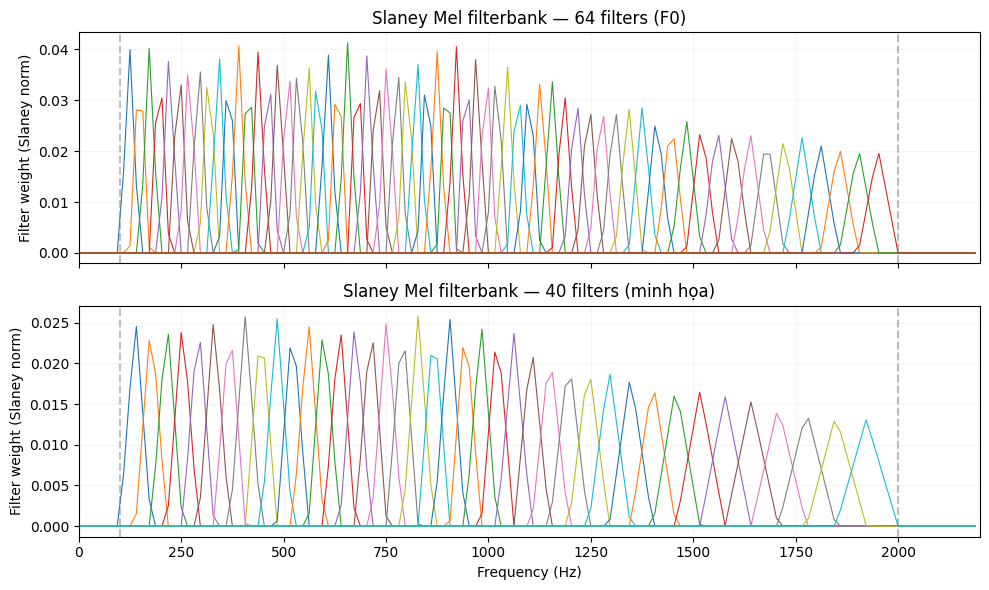

In [4]:
import librosa

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
mel_fft = FFT_F0  # Cố định FFT1024 của F0 để chỉ minh họa thay đổi n_mels
frequencies = librosa.fft_frequencies(sr=FS, n_fft=mel_fft)
visible = frequencies <= 2200
for ax, n_mels in zip(axes, [64, 40]):
    mel_filters = librosa.filters.mel(
        sr=FS,
        n_fft=mel_fft,
        n_mels=n_mels,
        fmin=LOW,
        fmax=HIGH,
        htk=False,
        norm='slaney',
    )
    for curve in mel_filters:
        ax.plot(frequencies[visible], curve[visible], linewidth=0.8)
    ax.axvline(LOW, linestyle='--', color='grey', alpha=0.5)
    ax.axvline(HIGH, linestyle='--', color='grey', alpha=0.5)
    ax.set(title=f'Slaney Mel filterbank — {n_mels} filters' + (' (F0)' if n_mels == 64 else ' (minh họa)'),
           ylabel='Filter weight (Slaney norm)', xlim=(0, 2200))
    ax.grid(alpha=0.12)
axes[-1].set_xlabel('Frequency (Hz)')
fig.tight_layout()
plt.show()

## A5. STFT, FFT và hop length: độ phân giải–chi phí

STFT tại frame `t` và bin tần số `k` được tính bởi:

$$
X[t,k] = Σ_{n=0}^{N_{FFT}-1}
x[n+tH]w[n]e^{-j2πkn/N_{FFT}}
$$

trong đó `H` là hop length và `w[n]` là cửa sổ Hann. Độ phân giải tần số và thời lượng cửa sổ là:

$$
Δf = f_s/N_{FFT},
\quad T_{window} = N_{FFT}/f_s
$$

Với `center=True`, tín hiệu được đệm `N_{FFT}/2` mẫu ở mỗi phía. Khi đó số frame của pipeline hiện tại là:

$$
N_{frame} = 1 + floor(N_{sample}/H)
$$

nên `N_sample=80.000` và `H=625` cho `129` frame. Tensor đầu vào có kích thước:

$$
N_{input} = N_{mel} × N_{frame} × 1
$$

Ở **F0**, `n_fft=1024` cho `Δf=15,625 Hz` và cửa sổ Hann `64 ms`. Giá trị 2048 được dùng **chỉ để minh họa thay đổi tham số**: `Δf=7,8125 Hz`, nhưng cửa sổ tăng thành `128 ms`. Vì số frame phụ thuộc hop và cơ chế padding, cả hai trường hợp vẫn có 129 frame. FFT dài hơn không mặc nhiên đảm bảo Accuracy tốt hơn; `Invoke()` cũng không bao gồm DSP.

In [5]:
checks=pd.DataFrame({
    'n_fft':[1024,2048],
    'delta_f_Hz':[FS/n for n in (1024,2048)],
    'Hann_window_ms':[1000*n/FS for n in (1024,2048)],
    'n_mels_example':[64,40],
    'frames_center_true':[1+N_SAMPLES//HOP]*2,
    'input_elements':[64*(1+N_SAMPLES//HOP),40*(1+N_SAMPLES//HOP)],
})
display(checks)
print('Giảm phần tử Mel input (64→40): {:.1f}%'.format(100*(1-40/64)))

,n_fft,delta_f_Hz,Hann_window_ms,n_mels_example,frames_center_true,input_elements
0,1024,15.6250,64.0,64,129,8256
1,2048,7.8125,128.0,40,129,5160


Giảm phần tử Mel input (64→40): 37.5%


## A6. Hình minh họa lưu trữ từ nghiên cứu ban đầu

Các hình sau được **giữ nguyên từ những phiên bản A trước khi tái cấu trúc**, nhằm lưu dấu những mô phỏng và cách trình bày từng được sử dụng trong giai đoạn xây dựng F0. Không đồng nhất những hình lưu trữ này với output mới của các code cell phía trên. Việc kiểm toán sample rate/băng thông nguồn WAV được trình bày độc lập tại **B0**.

**Hình A.1 — Đáp ứng Butterworth bậc lọc**

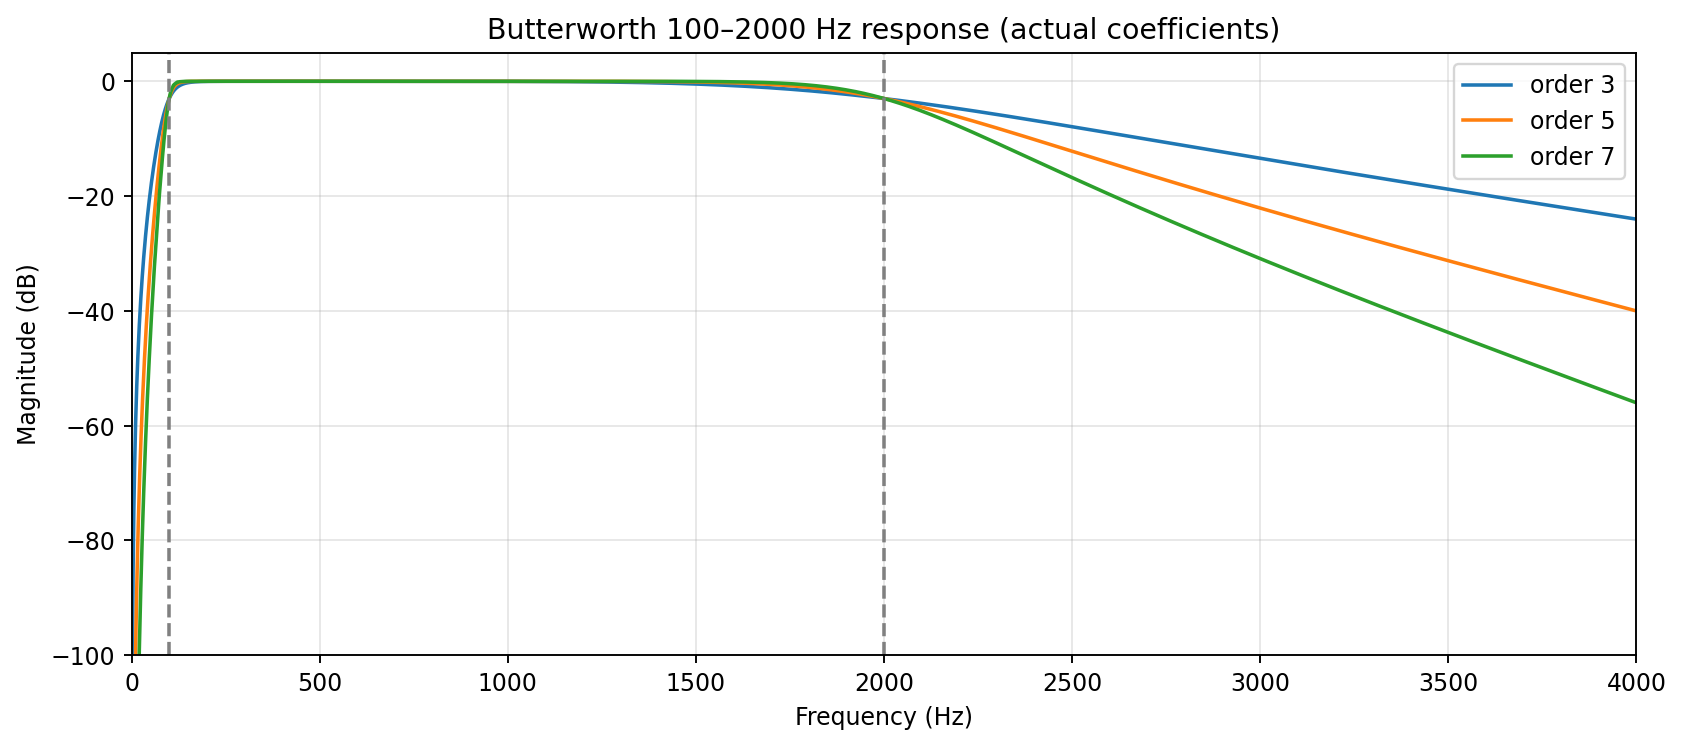

**Hình A.2 — Đáp ứng pre-emphasis — hình nghiên cứu cũ**

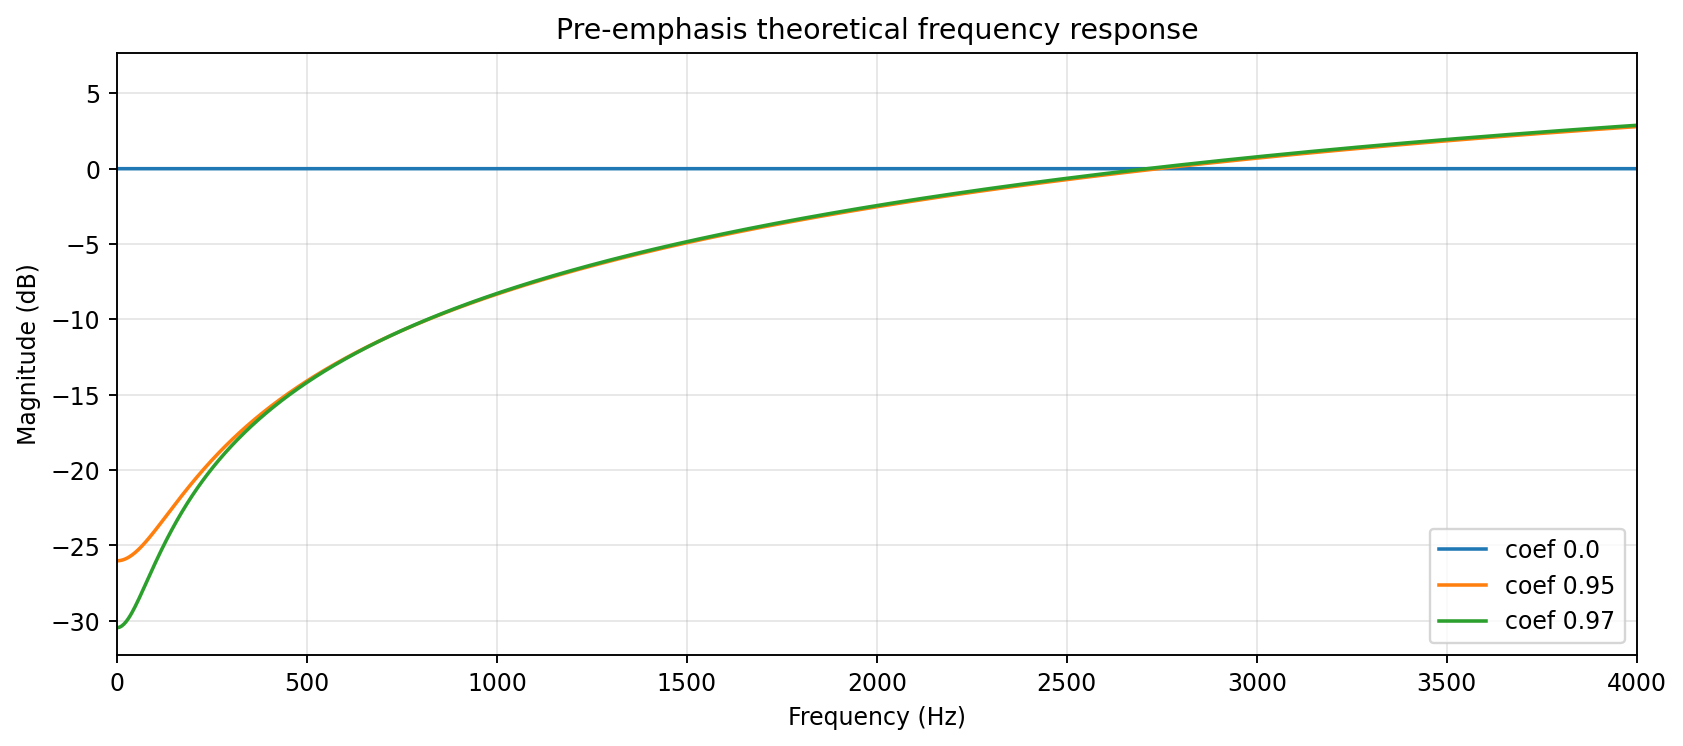

**Hình A.3 — Mel filterbank**

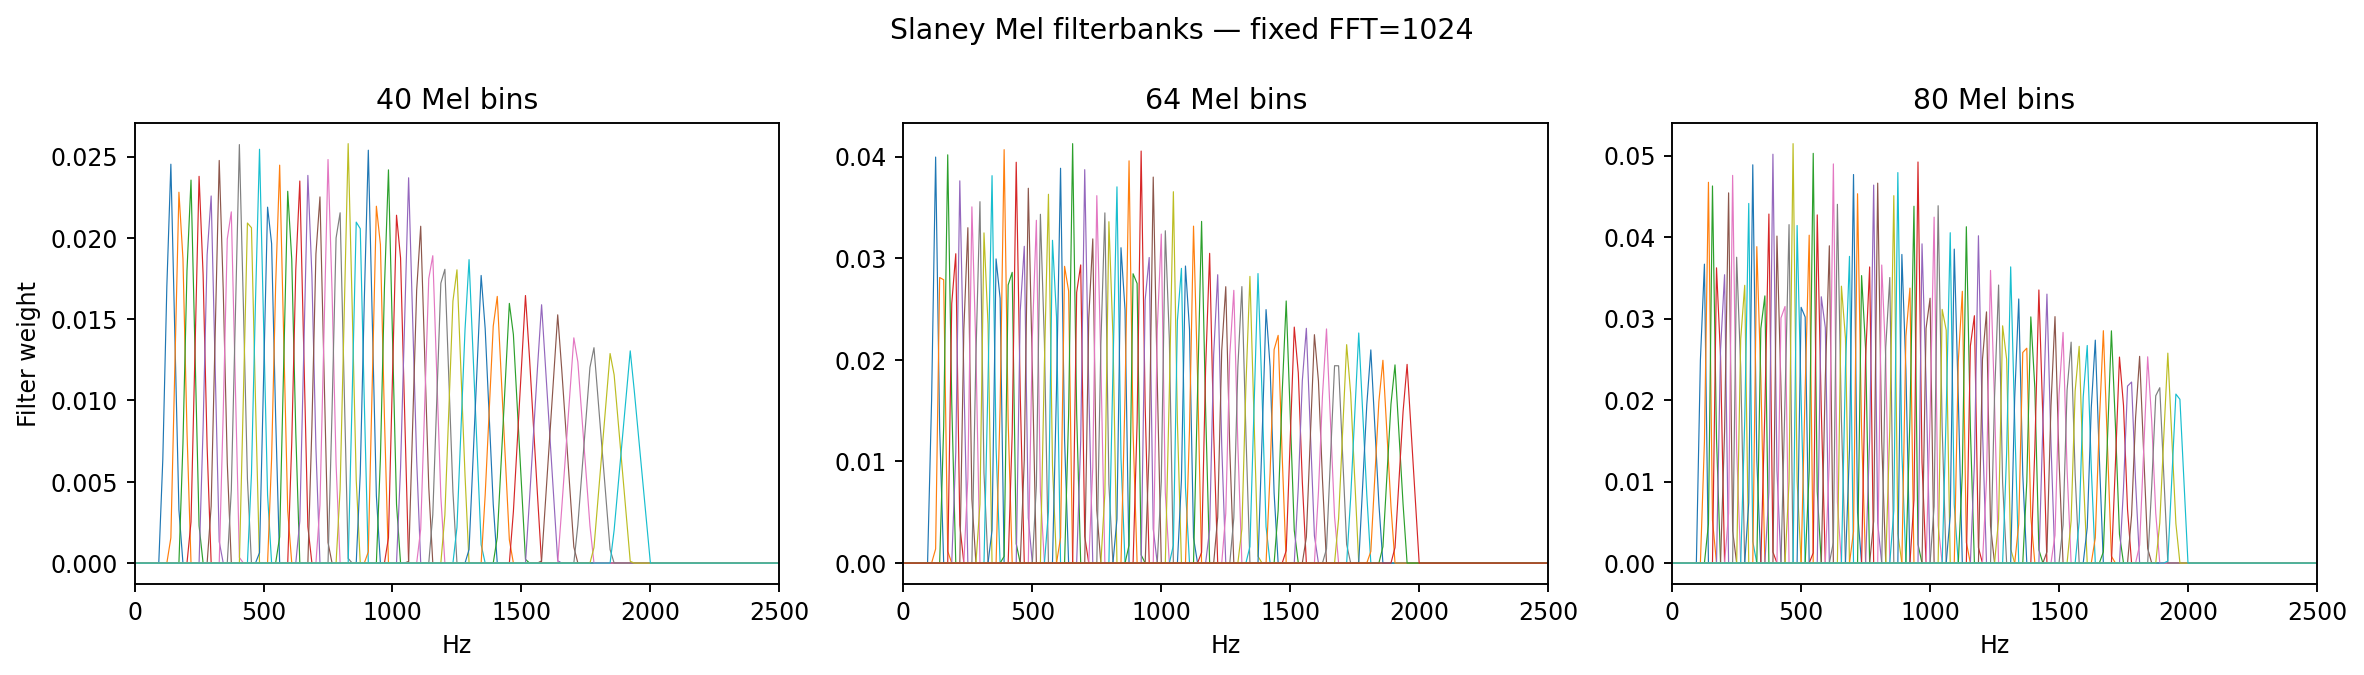

**Hình A.4 — Số dải Mel và cách phủ phổ**

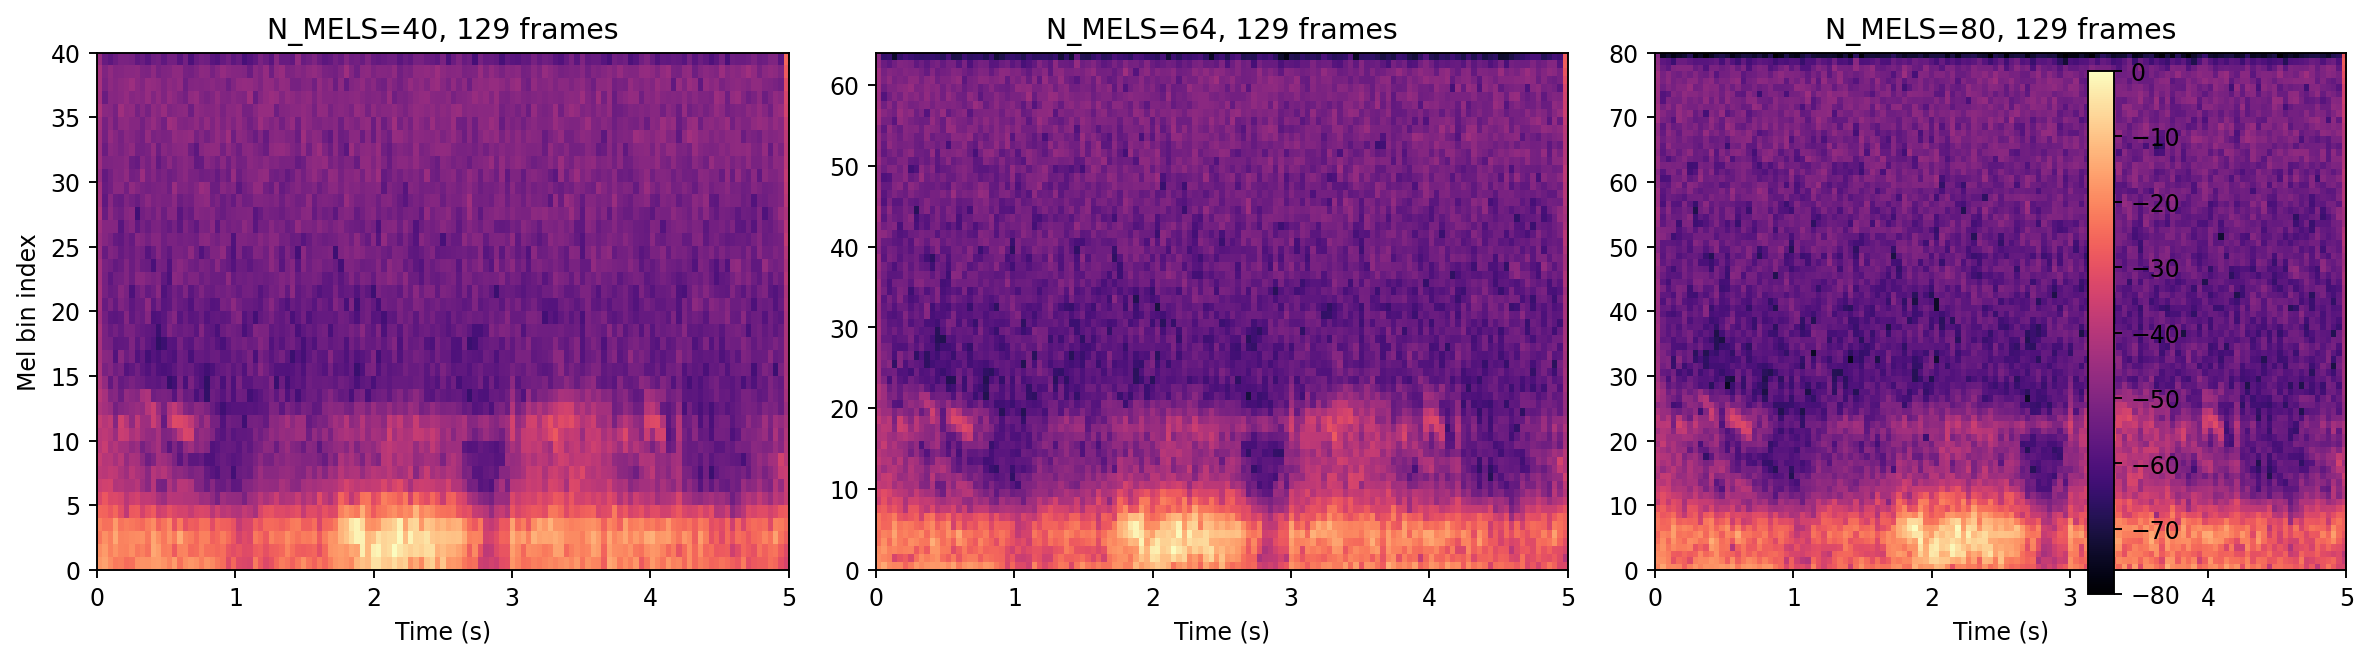

**Hình A.5 — Hop length và số frame**

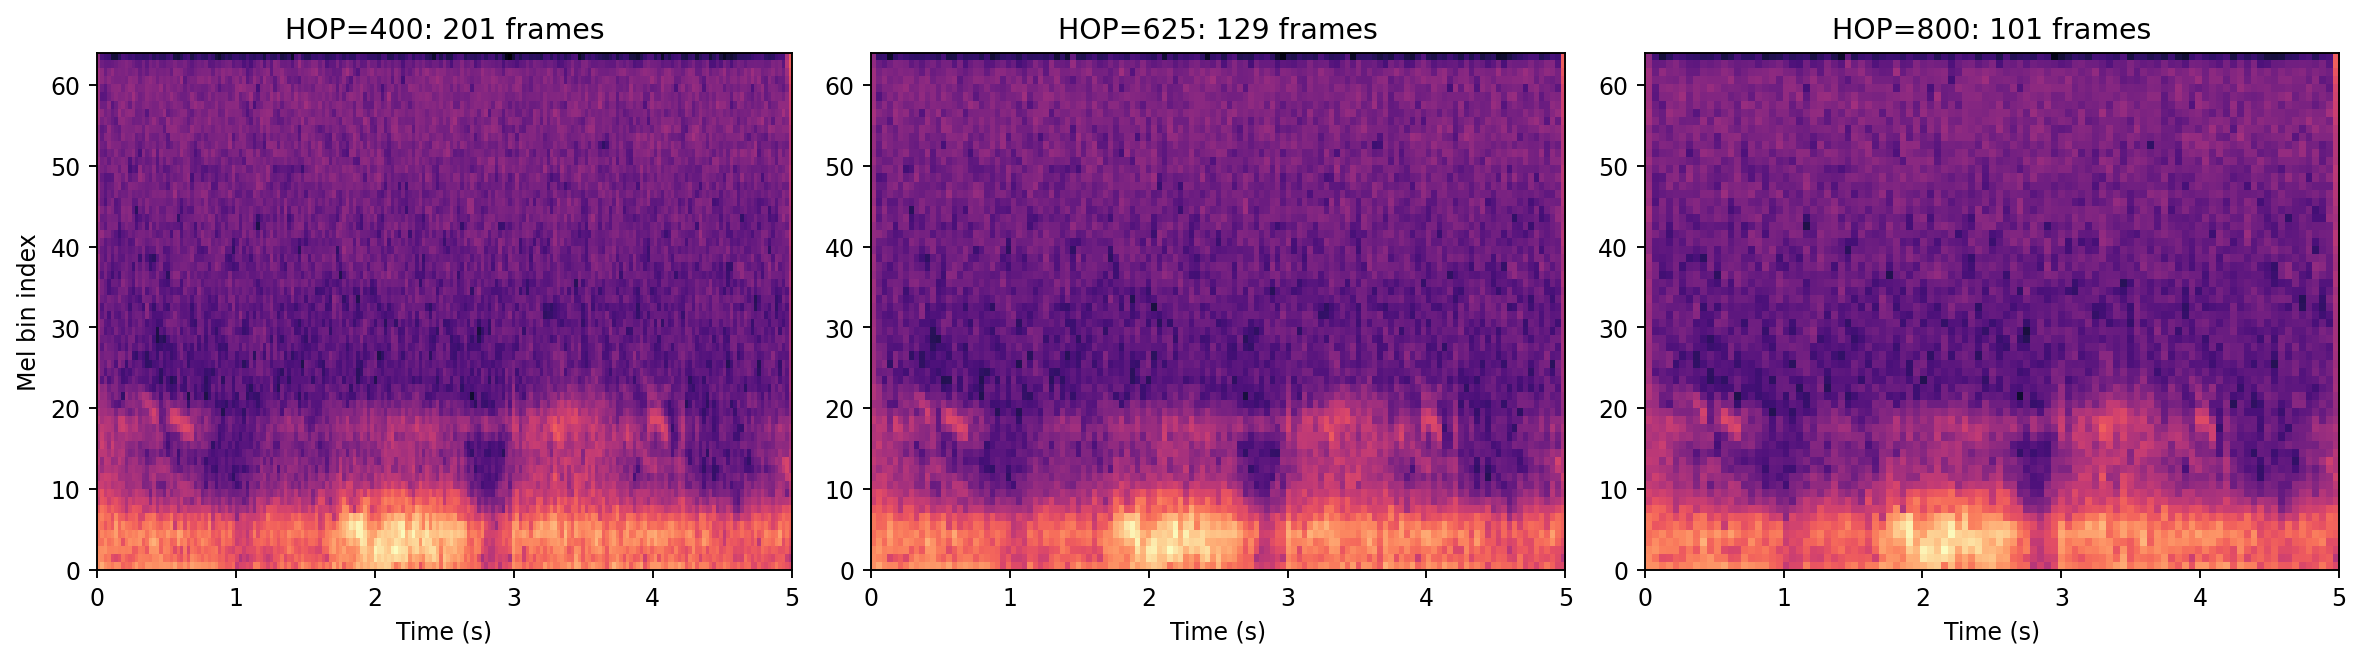

**Hình A.6 — FFT và biểu diễn Mel**

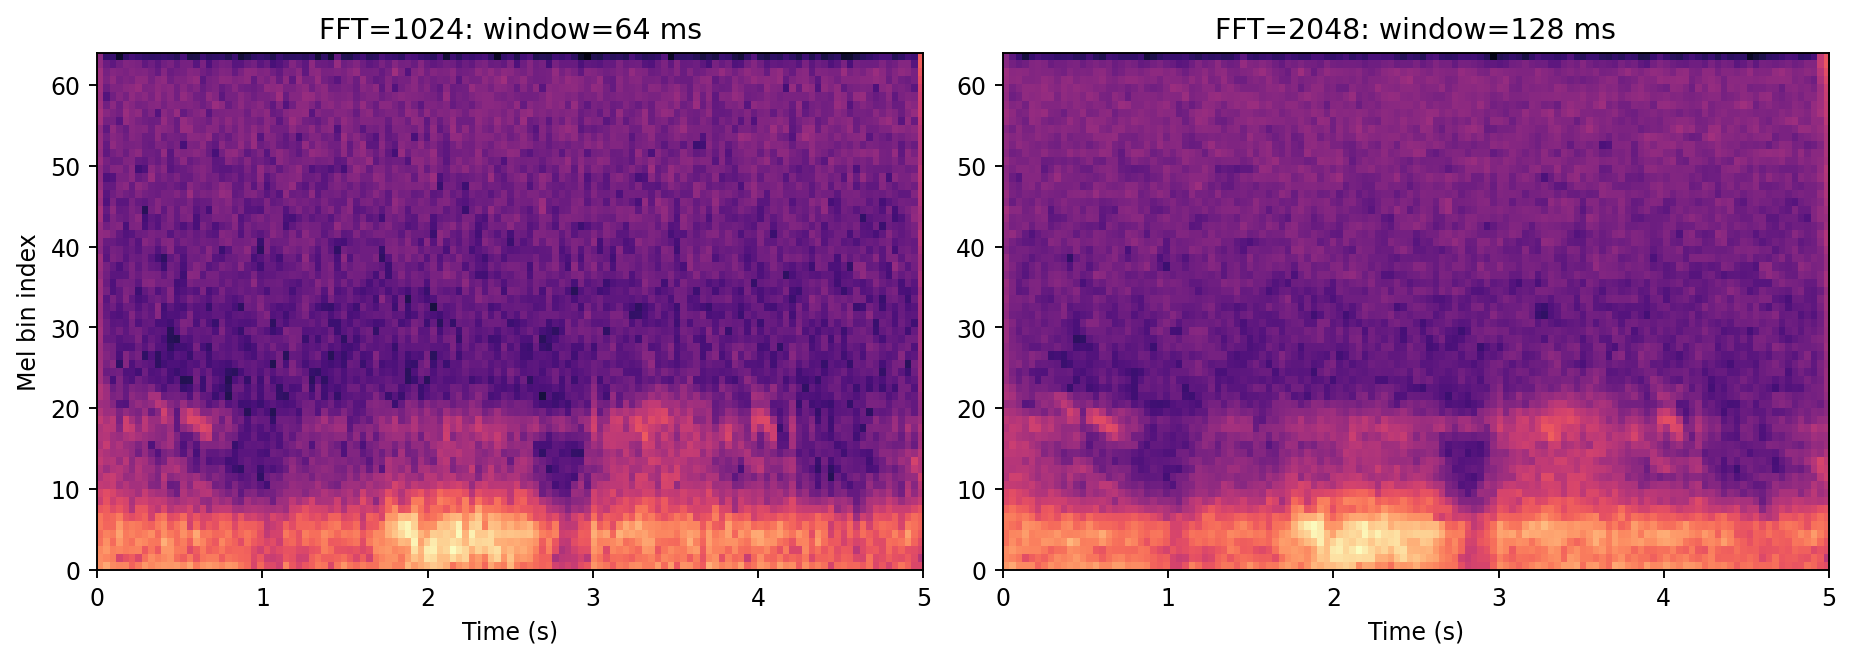

**Hình A.7 — Log-Mel so với MFCC, Δ và Δ²**

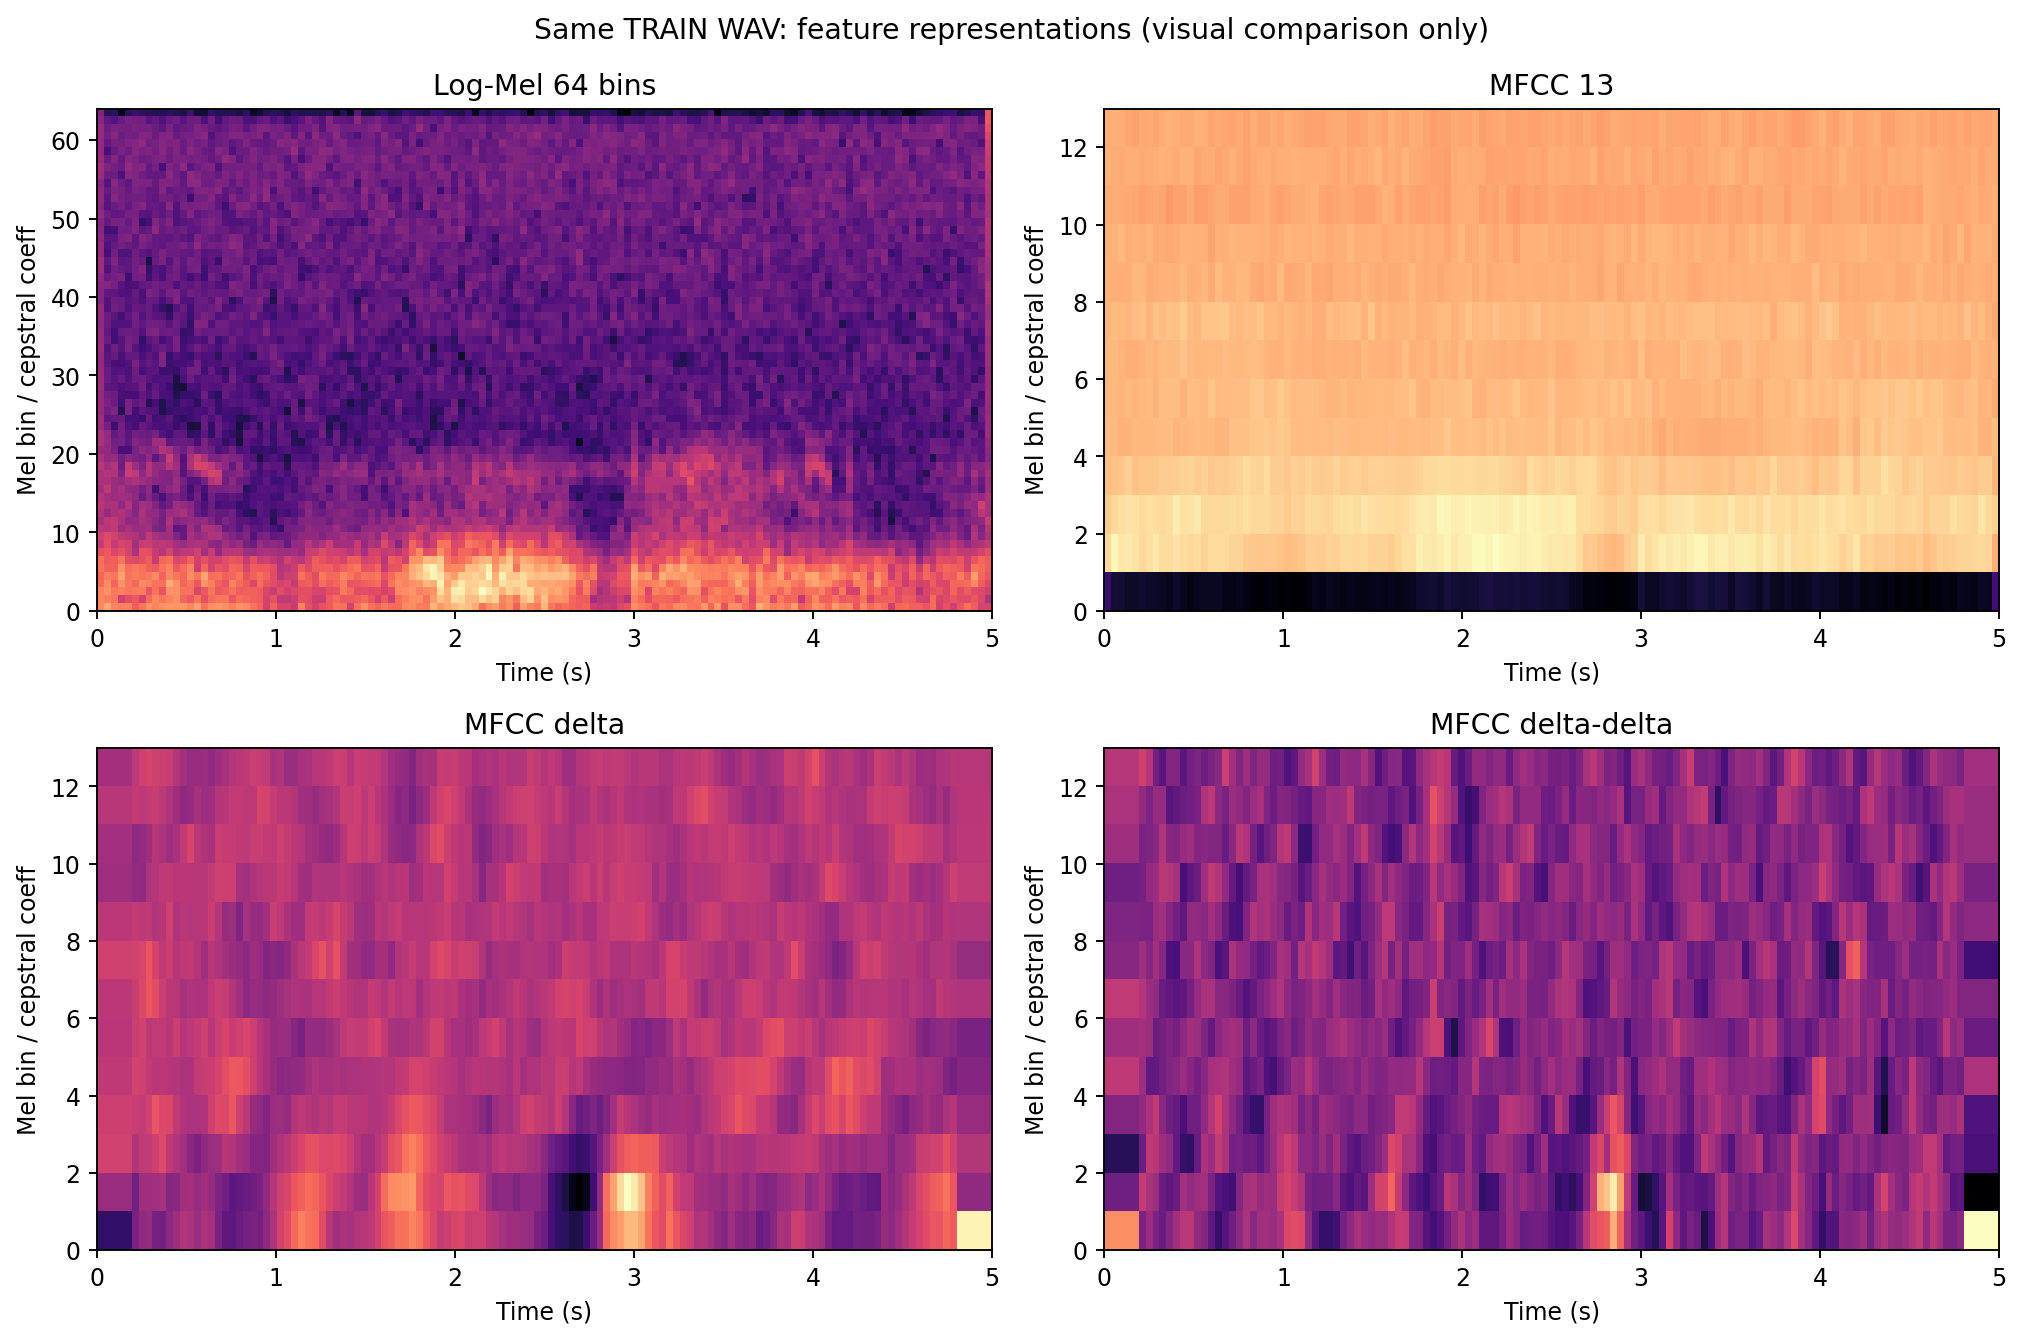

## A7. Kết luận: xác lập baseline F0/V1/s42 và bàn giao B

Cấu hình xuất phát **F0** gồm **mono 16 kHz/5 giây, Butterworth bậc 5 ở 100–2000 Hz, pre-emphasis α=0,97, 64 Mel, FFT1024 và hop625**. Riêng dải 100–2000 Hz có ba cơ sở: (i) tiếng rít có thành phần từ vài trăm đến trên 1 kHz; (ii) tiền lệ **Pramono và cs. (2019)** sử dụng bậc 5 và **150–2000 Hz**; (iii) khảo sát bổ sung **881 WAV Core TRAIN** cho thấy tỷ lệ năng lượng rất lớn dưới 100 Hz, trong khi băng thông khả dụng của nhiều WAV gốc dừng ở 2000 Hz.

**Giới hạn:** các phổ và ví dụ RMS không chứng minh rằng vùng dưới 100 Hz hoàn toàn là nhiễu, không bảo đảm giữ mọi thành phần wheeze trên 2000 Hz và **không chứng minh tối ưu Accuracy**. Sự mất cân bằng sample rate giữa hai nhãn là nguy cơ nhiễu do nguồn ghi, cần đọc cùng **B0**. Khảo sát band-pass được bổ sung nhằm lý giải F0, **không thay đổi dải lọc hồi cứu** sau khi biết kết quả các vòng sau.

Với F0, vòng khảo sát kiến trúc lịch sử cố định sơ bộ **V1 (Separable CNN + Flatten)** để tiến hành nghiên cứu Front-End. V1 **không có Test Accuracy cao nhất** ở vòng lịch sử; lựa chọn này chỉ có vai trò chuẩn hóa kiến trúc thử nghiệm, chưa chứng minh latency hoặc ưu thế phần cứng. Seed **42** là seed tham chiếu cho OFAT ban đầu.

**Bàn giao:** **B0** kiểm toán nguồn dữ liệu; **B** khảo sát OFAT từ **F0/V1/s42**; **C** đánh giá tổ hợp/multiple seed; **D** lượng tử hóa và kiểm thử tĩnh; **E** kiểm chứng và chọn model triển khai. Notebook A chỉ xác lập **cơ sở và giả thuyết**, không suy ngược kết quả lựa chọn cuối về baseline ban đầu.
